# Exercise 2: Manifold Learning

**Note**: Please insert the names of all participating students:

1. Nihad Beddeiwi
2. Tom Boje
3. Hannah
4. Amadou
5. Sören

In [ ]:
import sys, os
if 'google.colab' in sys.modules:
  if os.getcwd() == '/content':
    !git clone 'https://github.com/inb-luebeck/cs5450.git'
    os.chdir('cs5450')

## Exercise 2.1: Multi-dimensional Scaling (MDS)

In this exercise, we will implement Multi-dimensional Scaling.

Implement the missing parts below. When done correctly, your code should do the following:
1. Generate a swiss roll dataset.
2. Compute the squared euclidean distances between samples.
3. Compute the gram matrix from squared distances and the centering matrix.
4. Sort the eigenvalues and corresponding eigenvectors of the gram matrix.
5. Calculate the MDS data representation with reduced dimensions.
6. Show the lower-dimensional representation of the data.

In case you are struggeling with the task, here are some helpful tips and hints:
1. Useful functions: [`make_swiss_roll`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_swiss_roll.html), [`pdist`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.pdist.html), [`squareform`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.squareform.html), [`numpy.eye`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.eye.html), [`numpy.ones`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.ones.html), [`numpy.linalg.eig`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.eig.html), [`numpy.argsort`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.argsort.html), [`numpy.sqrt`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.sqrt.html), [`numpy.diag`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.diag.html), [`Axes.scatter`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.axes.Axes.scatter.html#matplotlib.axes.Axes.scatter), [`Axes3D.scatter`](https://matplotlib.org/3.1.1/api/_as_gen/mpl_toolkits.mplot3d.axes3d.Axes3D.html#mpl_toolkits.mplot3d.axes3d.Axes3D.scatter)

2. Additional references: [Color maps for matplotlib](https://matplotlib.org/examples/color/colormaps_reference.html)

Note: Don't use the MDS implementation provided by the sklearn package here.

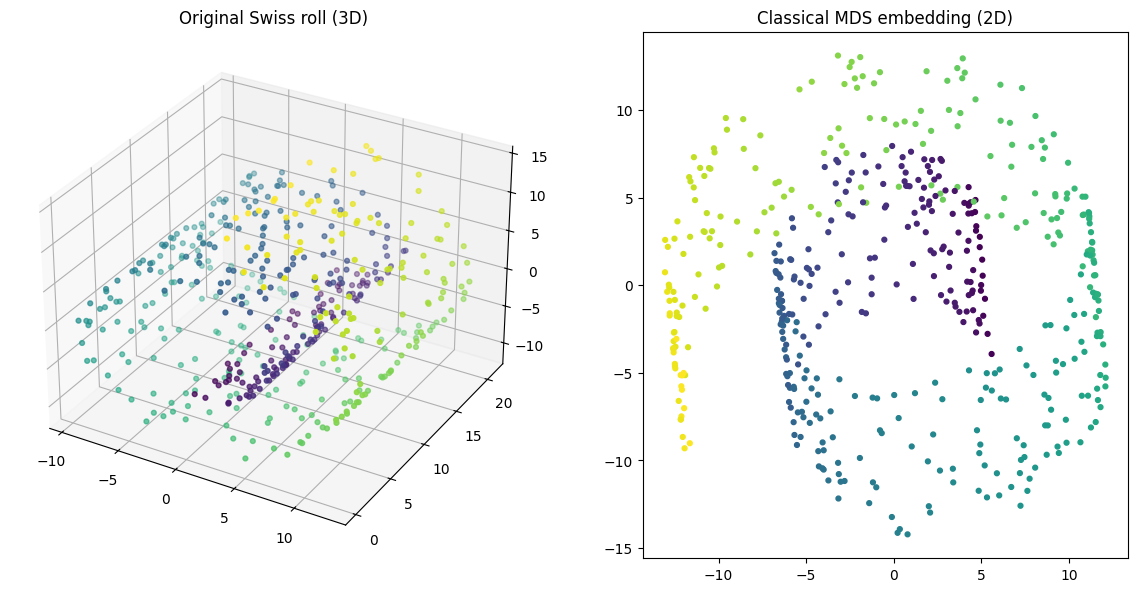

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import make_swiss_roll

n_samples = 500
n_dims = 2

data, color = make_swiss_roll(n_samples=n_samples, random_state=42)

# Compute pairwise squared Euclidean distances.
distances = pdist(data, metric="euclidean")
distances = squareform(distances)
distances_squared = distances**2

# Double-center the squared distances to obtain the Gram matrix.
I = np.eye(n_samples)
O = np.ones((n_samples, n_samples))
centering = I - O / n_samples
gram = -0.5 * centering @ distances_squared @ centering

# Use the symmetric eigensolver and sort eigenpairs in descending order.
eig_values, eig_vectors = np.linalg.eigh(gram)
permutation = np.argsort(eig_values)[::-1]
eig_vectors = eig_vectors[:, permutation]
eig_values = eig_values[permutation]

# Scale the leading eigenvectors by the roots of their eigenvalues.
epsilon = 0.001
eig_values_root = np.sqrt(eig_values[:n_dims] + epsilon)
data_mds = eig_vectors[:, :n_dims] * eig_values_root

fig = plt.figure(figsize=(12, 6))

ax = fig.add_subplot(121, projection="3d")
ax.scatter(data[:, 0], data[:, 1], data[:, 2], c=color, cmap="viridis", s=12)
ax.set_title("Original Swiss roll (3D)")

ax = fig.add_subplot(122)
ax.scatter(data_mds[:, 0], data_mds[:, 1], c=color, cmap="viridis", s=12)
ax.set_title("Classical MDS embedding (2D)")
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
plt.show()

## Exercise 2.2: Isomap

In this exercise, we will be implementing the Isomap algorithm.

You can use the MDS implementation from sklearn within your Isomap implementation.

Implement the missing parts below. When done correctly, your code should do the following:
1. Generate a swiss roll dataset.
2. Compute the euclidean distances between samples.
3. Sort the neighbors of each sample by distance.
4. Keep the closest k neighbors of each sample and set all other distances to infinity or NaN or zero to mark them as not-connected.
5. Calculate all shortest paths between pairs of samples (representing geodesic distances on the manifold).
6. Calculate the MDS data representation with reduced dimensions on the geodesic distances.
7. Show the lower-dimensional representation of the data.

In case you are struggeling with the task, here are some helpful tips and hints:
1. Useful functions:[`csgraph_from_dense`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.csgraph_from_dense.html), [`shortest_path`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.shortest_path.html#scipy.sparse.csgraph.shortest_path), [`MDS`](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
2. Make sure to use MDS with `dissimilarity='precomputed'` so that it takes a distance matrix as input instead of a matrix of sample coordinates.

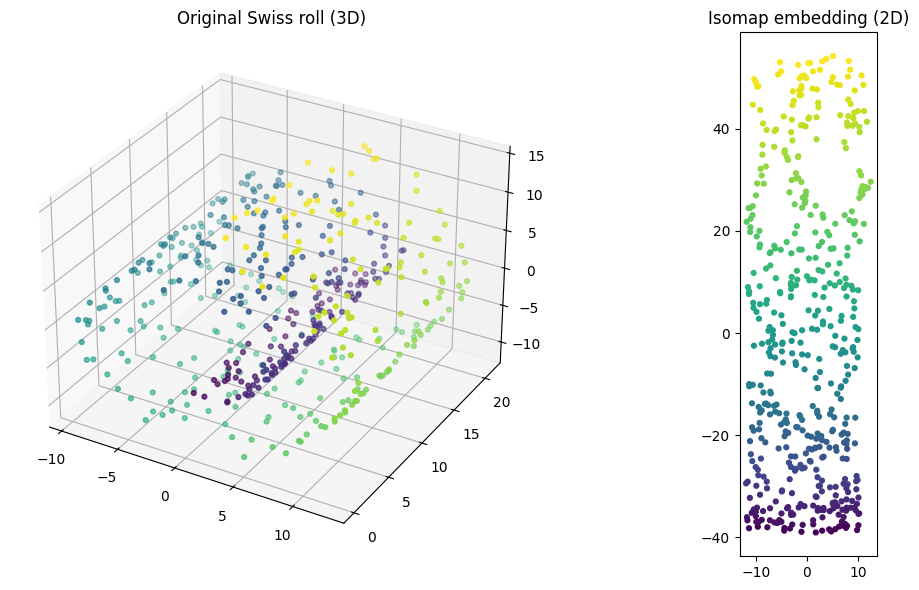

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import csgraph_from_dense, shortest_path
from sklearn.manifold import MDS
from sklearn.datasets import make_swiss_roll

n_samples = 500
n_dims = 2
n_neighbors = 8

data, color = make_swiss_roll(n_samples=n_samples, random_state=42)

# Compute pairwise Euclidean distances.
distances = pdist(data, metric="euclidean")
distances = squareform(distances)

# Exclude each sample from its own neighbor list before sorting.
np.fill_diagonal(distances, np.inf)
permutation = np.argsort(distances, axis=1)

# Keep only the k closest neighbors in each row. Zero means no edge.
distances_local = np.zeros_like(distances)
for i in range(n_samples):
    indices = permutation[i, :n_neighbors]
    distances_local[i, indices] = distances[i, indices]

# Keep an undirected edge if either endpoint selected the other.
distances_local = np.maximum(distances_local, distances_local.T)

graph = csgraph_from_dense(distances_local, null_value=0)
distances_geodesic = shortest_path(graph, method="D", directed=False)
assert np.isfinite(distances_geodesic).all(), (
    "Error: manifold is fragmented into multiple disconnected regions."
)

embedding = MDS(
    n_components=n_dims,
    dissimilarity="precomputed",
    n_init=4,
    random_state=42,
)
data_isomap = embedding.fit_transform(distances_geodesic)

fig = plt.figure(figsize=(12, 6))

ax = fig.add_subplot(121, projection="3d")
ax.scatter(data[:, 0], data[:, 1], data[:, 2], c=color, cmap="viridis", s=12)
ax.set_title("Original Swiss roll (3D)")

ax = fig.add_subplot(122)
ax.scatter(data_isomap[:, 0], data_isomap[:, 1], c=color, cmap="viridis", s=12)
ax.set_title("Isomap embedding (2D)")
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
plt.show()

## Exercise 2.3: Comprehension Questions

Answer the following comprehension questions either with right or wrong and briefly explain your decision:

1. A manifold is a topological space that locally resembles Euclidean space near each point, e.g. a sphere.

Right. Every point on the surface of a sphere has a neighborhood homeomorphic to an open disk in \(\mathbb{R}^2\), so the sphere is a 2D manifold.

2. The features found by classical MDS are equivalent to the ones computed by ICA.

Wrong. Classical MDS finds coordinates that preserve pairwise distances as closely as possible. ICA finds components that are as statistically independent as possible.

3. Isomap replaces the Euclidean distance measure used by MDS with geodesic distances.

Right. Isomap applies MDS to approximate geodesic distances computed as shortest paths through a nearest-neighbor graph.

4. Local Linear Embedding (LLE) seeks a lower-dimensional projection of the data trying to preserve the distances within a local neighborhood.

[Your answer]

5. Unlike MDS, LLE uses global properties of the manifold to find an embedding.

Wrong. LLE preserves the weights used to reconstruct each point as a linear combination of its neighbors. Its objective does not directly preserve local pairwise distances.

6. $n+1$ non-collinear points of two distinct classes are always linearly separable in $\mathbb{R}^n$.

Correct. LLE carries the original reconstruction weights into the lower-dimensional embedding and minimizes the reconstruction error there.

7. The reason that the kernel trick can be applied is that the observations only show up in pairs of inner products.

Right. When an algorithm uses observations only through inner products, a kernel can compute those inner products in a feature space without explicitly mapping the observations into it.

8-Wrong. A valid kernel computes \(k(x,y)=\langle \Phi(x),\Phi(y)\rangle\) directly, so an explicit formula for \(\Phi\) is unnecessary.

9. The function $\boldsymbol{\Phi} \left( \vec{x} \right) = \boldsymbol{\Phi} \left( \left[x_1, x_2 \right] \right) = \left[ x_1^2, \sqrt{2} x_1 x_2, x_2^2\right]$ is a function of the kernel $K \left( \vec{x}, \vec{y} \right) = \langle \vec{x}, \vec{y}\rangle^2$. This function is unique.

**Wrong.** The given feature map realizes the kernel \(K(x,y)=(x^\top y)^2\). It is one of many possible maps, since any orthogonal transformation of its output preserves the same inner products.